In [1]:
# Importacao das bibliotecas e configuracoes
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

sns.set_theme(style='whitegrid')


In [2]:
# Carregamento da base de dados de turismo direto da web
url = 'https://gist.githubusercontent.com/Yuri-Sanchez/026bd9aff0777b22f148efb3dab7005b/raw/dados_turismo.csv'
df = pd.read_csv(url)
df.head()


,id_reserva,tipo_hospedagem,cancelado,dias_antecedencia,ano_chegada,mes_chegada,noites_fim_semana,noites_dias_uteis,qtd_adultos,qtd_criancas,pais_origem,canal_reserva,cliente_retorno,tipo_quarto,valor_diaria,pedidos_especiais
0,1001,Resort,0,107,2015,Julho,2,5,2,0,Portugal,Agência Online,0,A,575.64,2
1,1002,Resort,0,9,2015,Julho,0,1,2,0,Portugal,Agência Online,0,A,509.60,2
2,1003,Resort,0,9,2015,Julho,1,0,1,0,Alemanha,Agência Online,0,A,462.80,0
3,1004,Resort,0,104,2015,Julho,1,5,2,0,Portugal,Agência Online,0,E,611.68,0
4,1005,Resort,0,96,2015,Julho,2,5,2,0,Reino Unido,Agência Online,0,E,556.40,1


In [3]:
# Informacoes gerais e valores nulos iniciais
print(df.info())
print('--- Valores nulos encontrados: ---')
print(df.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 2681 entries, 0 to 2680
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_reserva         2681 non-null   int64  
 1   tipo_hospedagem    2681 non-null   str    
 2   cancelado          2681 non-null   int64  
 3   dias_antecedencia  2681 non-null   int64  
 4   ano_chegada        2681 non-null   int64  
 5   mes_chegada        2681 non-null   str    
 6   noites_fim_semana  2681 non-null   int64  
 7   noites_dias_uteis  2681 non-null   int64  
 8   qtd_adultos        2681 non-null   int64  
 9   qtd_criancas       2681 non-null   int64  
 10  pais_origem        2602 non-null   str    
 11  canal_reserva      2681 non-null   str    
 12  cliente_retorno    2681 non-null   int64  
 13  tipo_quarto        2681 non-null   str    
 14  valor_diaria       2663 non-null   float64
 15  pedidos_especiais  2681 non-null   int64  
dtypes: float64(1), int64(10), str(5)
me

In [4]:
# Verificando e removendo registros duplicados
duplicados = df.duplicated().sum()
print('Total de registros duplicados encontrados:', duplicados)
df.drop_duplicates(inplace=True)
print('Total de registros apos remocao:', len(df))


Total de registros duplicados encontrados: 28
Total de registros apos remocao: 2653


In [5]:
# Tratamento de valores faltantes (nulos)
df['pais_origem'] = df['pais_origem'].fillna('Não Informado')
mediana_diaria = df['valor_diaria'].median()
df['valor_diaria'] = df['valor_diaria'].fillna(mediana_diaria)
df['qtd_criancas'] = df['qtd_criancas'].fillna(0)

print('Valores nulos apos tratamento:')
print(df.isnull().sum())


Valores nulos apos tratamento:
id_reserva           0
tipo_hospedagem      0
cancelado            0
dias_antecedencia    0
ano_chegada          0
mes_chegada          0
noites_fim_semana    0
noites_dias_uteis    0
qtd_adultos          0
qtd_criancas         0
pais_origem          0
canal_reserva        0
cliente_retorno      0
tipo_quarto          0
valor_diaria         0
pedidos_especiais    0
dtype: int64


In [6]:
# Criando novas colunas para enriquecer a analise (Feature Engineering)
df['total_noites'] = df['noites_fim_semana'] + df['noites_dias_uteis']
df['total_hospedes'] = df['qtd_adultos'] + df['qtd_criancas']
df.head()


,id_reserva,tipo_hospedagem,cancelado,dias_antecedencia,ano_chegada,mes_chegada,noites_fim_semana,noites_dias_uteis,qtd_adultos,qtd_criancas,pais_origem,canal_reserva,cliente_retorno,tipo_quarto,valor_diaria,pedidos_especiais,total_noites,total_hospedes
0,1001,Resort,0,107,2015,Julho,2,5,2,0,Portugal,Agência Online,0,A,575.64,2,7,2
1,1002,Resort,0,9,2015,Julho,0,1,2,0,Portugal,Agência Online,0,A,509.60,2,1,2
2,1003,Resort,0,9,2015,Julho,1,0,1,0,Alemanha,Agência Online,0,A,462.80,0,1,1
3,1004,Resort,0,104,2015,Julho,1,5,2,0,Portugal,Agência Online,0,E,611.68,0,6,2
4,1005,Resort,0,96,2015,Julho,2,5,2,0,Reino Unido,Agência Online,0,E,556.40,1,7,2


In [7]:
# Indicadores Principais (KPIs)
total_reservas = len(df)
total_canceladas = df['cancelado'].sum()
taxa_cancelamento = round(df['cancelado'].mean() * 100, 2)
diaria_media = round(df['valor_diaria'].mean(), 2)
estadia_media = round(df['total_noites'].mean(), 1)

print('========================================')
print('       INDICADORES PRINCIPAIS')
print('========================================')
print('1. Total de Reservas Validas:', total_reservas)
print('2. Taxa Geral de Cancelamento:', str(taxa_cancelamento) + '%', f'({total_canceladas} canceladas)')
print('3. Valor Medio da Diaria:     R$', diaria_media)
print('4. Media de Noites:           ', estadia_media, 'noites')
print('========================================')


       INDICADORES PRINCIPAIS
1. Total de Reservas Validas: 2653
2. Taxa Geral de Cancelamento: 37.09% (984 canceladas)
3. Valor Medio da Diaria:     R$ 539.32
4. Media de Noites:            3.4 noites


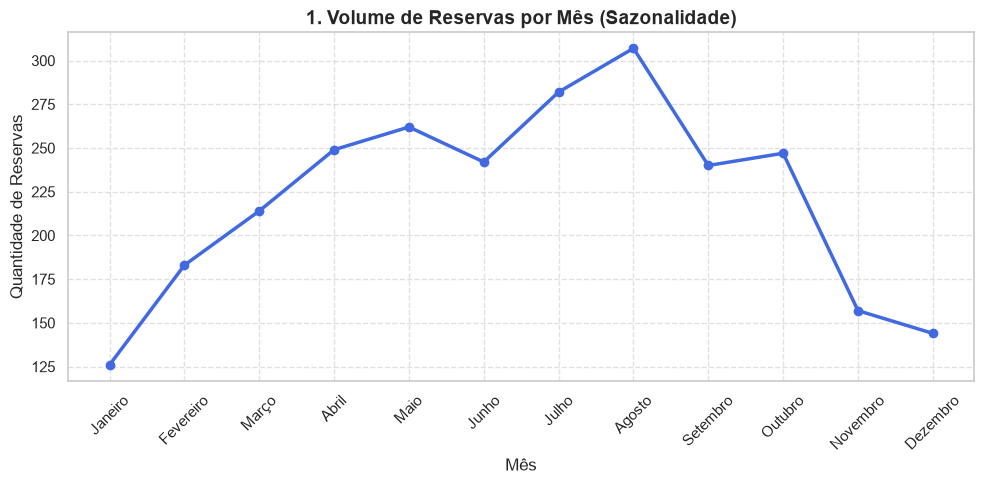

In [8]:
# Analise 1: Sazonalidade das Reservas por Mes
meses_ordem = ['Janeiro', 'Fevereiro', 'Março', 'Abril', 'Maio', 'Junho', 
               'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro']
reservas_mes = df['mes_chegada'].value_counts().reindex(meses_ordem)

plt.figure(figsize=(10, 5))
plt.plot(reservas_mes.index, reservas_mes.values, marker='o', color='royalblue', linewidth=2.5)
plt.title('1. Volume de Reservas por Mês (Sazonalidade)', fontsize=14, fontweight='bold')
plt.xlabel('Mês')
plt.ylabel('Quantidade de Reservas')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


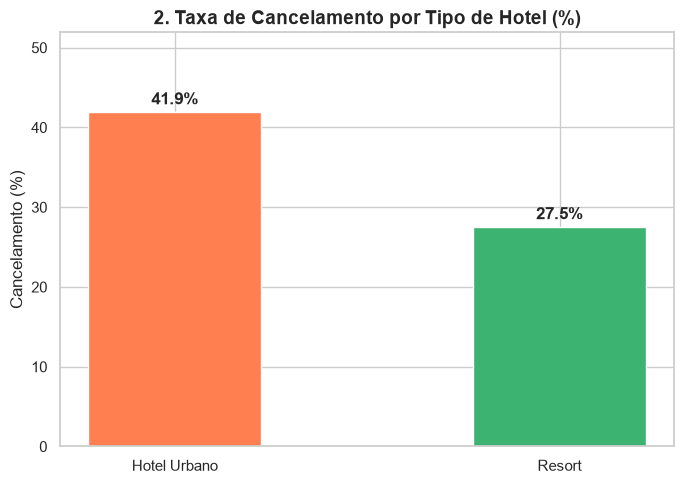

In [9]:
# Analise 2: Taxa de Cancelamento por Tipo de Hotel
canc_hotel = round(df.groupby('tipo_hospedagem')['cancelado'].mean() * 100, 1)

plt.figure(figsize=(7, 5))
barras = plt.bar(canc_hotel.index, canc_hotel.values, color=['coral', 'mediumseagreen'], width=0.45)
plt.title('2. Taxa de Cancelamento por Tipo de Hotel (%)', fontsize=14, fontweight='bold')
plt.ylabel('Cancelamento (%)')
plt.ylim(0, canc_hotel.max() + 10)

for b in barras:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 1, f'{b.get_height()}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


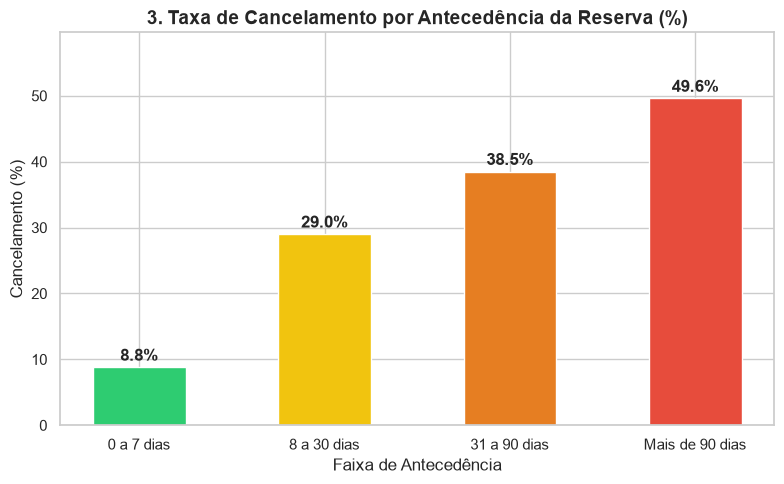

In [10]:
# Analise 3: Cancelamento por Antecedencia da Reserva
df['faixa_dias'] = pd.cut(df['dias_antecedencia'], 
                          bins=[-1, 7, 30, 90, 1000], 
                          labels=['0 a 7 dias', '8 a 30 dias', '31 a 90 dias', 'Mais de 90 dias'])
canc_ant = round(df.groupby('faixa_dias', observed=True)['cancelado'].mean() * 100, 1)

plt.figure(figsize=(8, 5))
barras_ant = plt.bar(canc_ant.index, canc_ant.values, color=['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c'], width=0.5)
plt.title('3. Taxa de Cancelamento por Antecedência da Reserva (%)', fontsize=14, fontweight='bold')
plt.xlabel('Faixa de Antecedência')
plt.ylabel('Cancelamento (%)')
plt.ylim(0, canc_ant.max() + 10)

for b in barras_ant:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 1, f'{b.get_height()}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


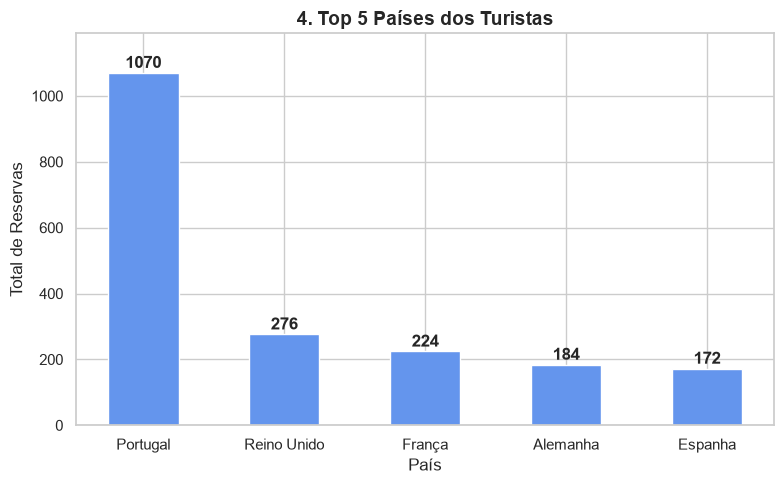

In [11]:
# Analise 4: Top 5 Paises de Origem dos Turistas
top_paises = df[df['pais_origem'] != 'Não Informado']['pais_origem'].value_counts().head(5)

plt.figure(figsize=(8, 5))
barras_p = plt.bar(top_paises.index, top_paises.values, color='cornflowerblue', width=0.5)
plt.title('4. Top 5 Países dos Turistas', fontsize=14, fontweight='bold')
plt.xlabel('País')
plt.ylabel('Total de Reservas')
plt.ylim(0, top_paises.max() + 120)

for b in barras_p:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 15, f'{int(b.get_height())}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


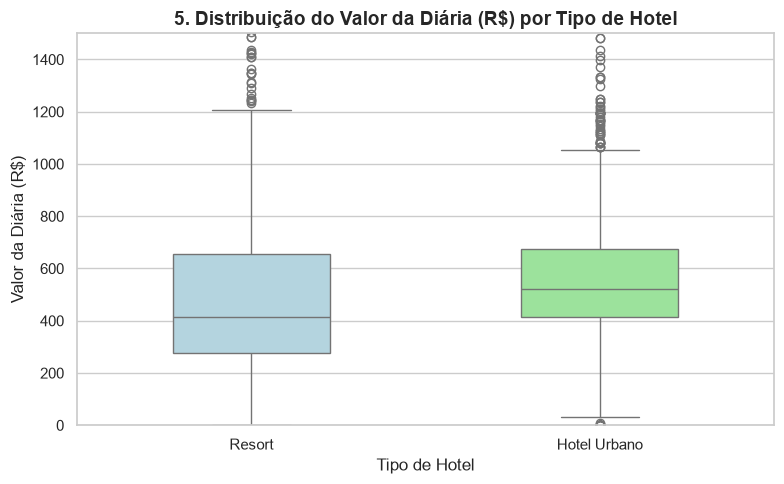

In [12]:
# Analise 5: Distribuicao do Valor da Diaria (R$) por Tipo de Hotel (Boxplot)
plt.figure(figsize=(8, 5))
sns.boxplot(x='tipo_hospedagem', y='valor_diaria', hue='tipo_hospedagem', data=df, 
            palette=['lightblue', 'lightgreen'], legend=False, width=0.45)
plt.title('5. Distribuição do Valor da Diária (R$) por Tipo de Hotel', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Hotel')
plt.ylabel('Valor da Diária (R$)')
plt.ylim(0, 1500)
plt.tight_layout()
plt.show()


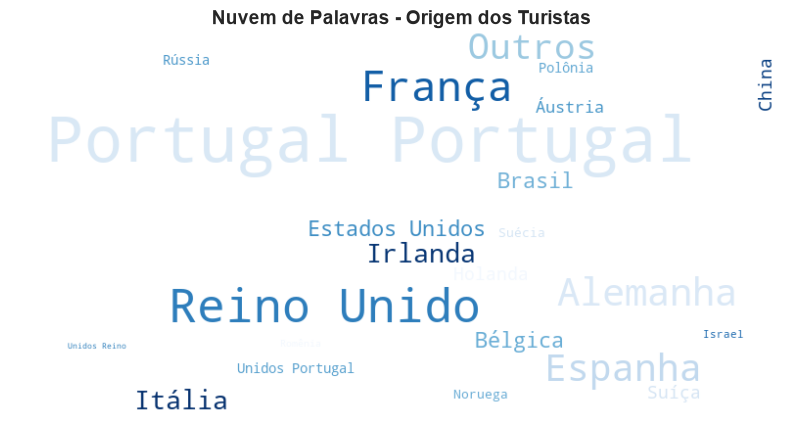

In [13]:
# Analise Bonus: Nuvem de Palavras dos Paises dos Turistas
texto_paises = ' '.join(df[df['pais_origem'] != 'Não Informado']['pais_origem'].dropna())
nuvem = WordCloud(width=800, height=400, background_color='white', colormap='Blues').generate(texto_paises)

plt.figure(figsize=(9, 4.5))
plt.imshow(nuvem, interpolation='bilinear')
plt.axis('off')
plt.title('Nuvem de Palavras - Origem dos Turistas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


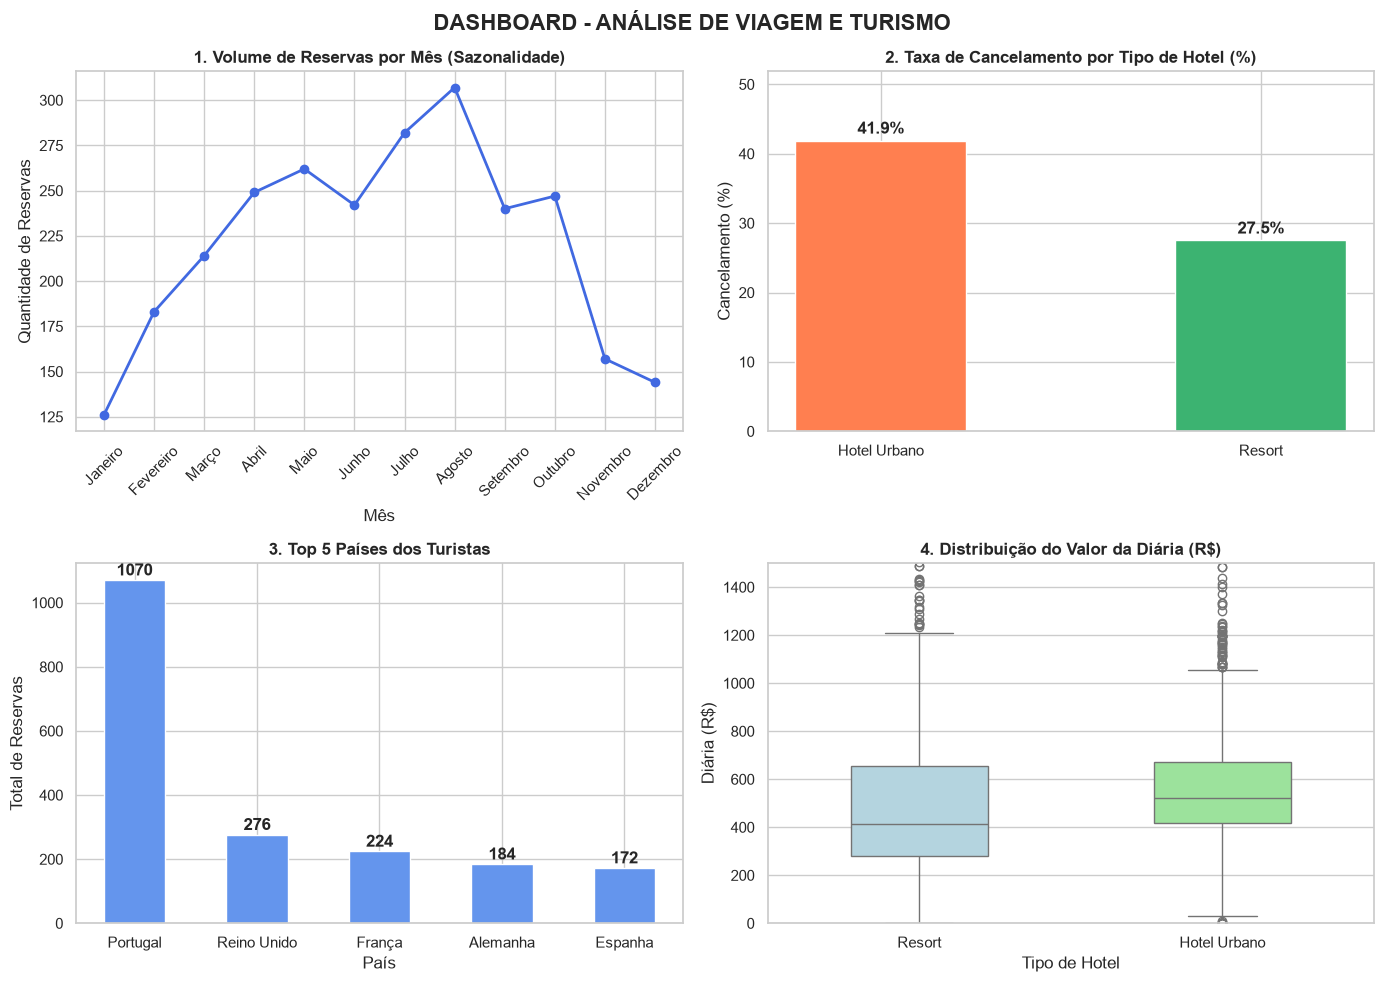

In [14]:
# DASHBOARD EXECUTIVO - 4 GRAFICOS EM UMA TELA SO
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('DASHBOARD - ANÁLISE DE VIAGEM E TURISMO', fontsize=16, fontweight='bold', y=0.98)

# 1. Volume de Reservas por Mes
axes[0, 0].plot(reservas_mes.index, reservas_mes.values, marker='o', color='royalblue', linewidth=2)
axes[0, 0].set_title('1. Volume de Reservas por Mês (Sazonalidade)', fontweight='bold')
axes[0, 0].set_xlabel('Mês')
axes[0, 0].set_ylabel('Quantidade de Reservas')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Taxa de Cancelamento por Tipo de Hotel
barras2 = axes[0, 1].bar(canc_hotel.index, canc_hotel.values, color=['coral', 'mediumseagreen'], width=0.45)
axes[0, 1].set_title('2. Taxa de Cancelamento por Tipo de Hotel (%)', fontweight='bold')
axes[0, 1].set_ylabel('Cancelamento (%)')
axes[0, 1].set_ylim(0, canc_hotel.max() + 10)
for b in barras2:
    axes[0, 1].text(b.get_x() + b.get_width()/2, b.get_height() + 1, f'{b.get_height()}%', ha='center', fontweight='bold')

# 3. Top 5 Paises de Origem
axes[1, 0].bar(top_paises.index, top_paises.values, color='cornflowerblue', width=0.5)
axes[1, 0].set_title('3. Top 5 Países dos Turistas', fontweight='bold')
axes[1, 0].set_xlabel('País')
axes[1, 0].set_ylabel('Total de Reservas')
for b in axes[1, 0].patches:
    axes[1, 0].text(b.get_x() + b.get_width()/2, b.get_height() + 15, f'{int(b.get_height())}', ha='center', fontweight='bold')

# 4. Boxplot do Valor da Diaria
sns.boxplot(x='tipo_hospedagem', y='valor_diaria', hue='tipo_hospedagem', data=df, 
            palette=['lightblue', 'lightgreen'], legend=False, ax=axes[1, 1], width=0.45)
axes[1, 1].set_title('4. Distribuição do Valor da Diária (R$)', fontweight='bold')
axes[1, 1].set_xlabel('Tipo de Hotel')
axes[1, 1].set_ylabel('Diária (R$)')
axes[1, 1].set_ylim(0, 1500)

plt.tight_layout()
plt.show()


In [15]:
# Conclusoes Finais do Trabalho
print("""
=============================================================================
                          PRINCIPAIS CONCLUSÕES
=============================================================================
1. Sazonalidade: Julho (282) e Agosto (307) concentram o pico de alta temporada.
2. Cancelamento: Hotéis urbanos cancelam significativamente mais (41,9%) que Resorts (27,5%).
3. Antecedência: Reservas feitas com mais de 90 dias cancelam quase metade (49,6%).
4. Turistas: Portugal (1.070), Reino Unido (276) e França (224) são os principais mercados.
5. Tomada de Decisão: Aplicar tarifas não-reembolsáveis com desconto para reservas de longo prazo
   e lançar pacotes promocionais na baixa temporada (Janeiro e Fevereiro).
=============================================================================
""")



                          PRINCIPAIS CONCLUSÕES
1. Sazonalidade: Julho (282) e Agosto (307) concentram o pico de alta temporada.
2. Cancelamento: Hotéis urbanos cancelam significativamente mais (41,9%) que Resorts (27,5%).
3. Antecedência: Reservas feitas com mais de 90 dias cancelam quase metade (49,6%).
4. Turistas: Portugal (1.070), Reino Unido (276) e França (224) são os principais mercados.
5. Tomada de Decisão: Aplicar tarifas não-reembolsáveis com desconto para reservas de longo prazo
   e lançar pacotes promocionais na baixa temporada (Janeiro e Fevereiro).

